<a href="https://colab.research.google.com/github/Eratofee/ChromaTone/blob/main/Markov_Chain_Example.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Install the Python library for creating and processing musical scores.
%pip -q install music21

import shutil
import subprocess
from music21 import environment

# Install MuseScore and the tools required to run it without a physical screen.
subprocess.run(
    ["apt-get", "update", "-qq"],
    check=True
)

subprocess.run(
    ["apt-get", "install", "-y", "-qq", "musescore3", "xvfb", "xauth"],
    check=True
)

# Find the MuseScore executable automatically.
MUSESCORE_PATH = next(
    (
        path
        for name in ["musescore3", "mscore3", "musescore", "mscore"]
        if (path := shutil.which(name))
    ),
    None
)

if MUSESCORE_PATH is None:
    raise RuntimeError("MuseScore executable was not found.")

if shutil.which("xvfb-run") is None:
    raise RuntimeError("The virtual screen tool xvfb-run was not found.")

# Configure music21 to use this MuseScore installation.
env = environment.Environment()
env["musescoreDirectPNGPath"] = MUSESCORE_PATH
env["musicxmlPath"] = MUSESCORE_PATH

print("MuseScore is ready:", MUSESCORE_PATH)

MuseScore is ready: /usr/bin/musescore3


In [2]:
import numpy as np
from music21 import metadata, note, stream


class MarkovChainMelodyGenerator:
    """
    Represents a Markov Chain model for melody generation.
    """

    def __init__(self, states):
        """
        Initialize the MarkovChain with a list of states.

        Parameters:
            states (list of tuples): A list of possible (pitch, duration)
                pairs.
        """
        self.states = states
        self.initial_probabilities = np.zeros(len(states))
        self.transition_matrix = np.zeros((len(states), len(states)))
        self._state_indexes = {state: i for (i, state) in enumerate(states)}

    def train(self, notes):
        """
        Train the model based on a list of notes.

        Parameters:
            notes (list): A list of music21.note.Note objects.
        """
        self._calculate_initial_probabilities(notes)
        self._calculate_transition_matrix(notes)

    def generate(self, length):
        """
        Generate a melody of a given length.

        Parameters:
            length (int): The length of the sequence to generate.

        Returns:
            melody (list of tuples): A list of generated states.
        """
        melody = [self._generate_starting_state()]
        for _ in range(1, length):
            melody.append(self._generate_next_state(melody[-1]))
        return melody

    def _calculate_initial_probabilities(self, notes):
        """
        Calculate the initial probabilities from the provided notes.

        Parameters:
            notes (list): A list of music21.note.Note objects.
        """
        for note in notes:
            self._increment_initial_probability_count(note)
        self._normalize_initial_probabilities()

    def _increment_initial_probability_count(self, note):
        """
        Increment the probability count for a given note.

        Parameters:
            note (music21.note.Note): A note object.
        """
        state = (note.pitch.nameWithOctave, note.duration.quarterLength)
        self.initial_probabilities[self._state_indexes[state]] += 1

    def _normalize_initial_probabilities(self):
        """
        Normalize the initial probabilities array such that the sum of all
        probabilities equals 1.
        """
        total = np.sum(self.initial_probabilities)
        if total:
            self.initial_probabilities /= total
        self.initial_probabilities = np.nan_to_num(self.initial_probabilities)

    def _calculate_transition_matrix(self, notes):
        """
        Calculate the transition matrix from the provided notes.

        Parameters:
            notes (list): A list of music21.note.Note objects.
        """
        for i in range(len(notes) - 1):
            self._increment_transition_count(notes[i], notes[i + 1])
        self._normalize_transition_matrix()

    def _increment_transition_count(self, current_note, next_note):
        """
        Increment the transition count from current_note to next_note.

        Parameters:
            current_note (music21.note.Note): The current note object.
            next_note (music21.note.Note): The next note object.
        """
        state = (
            current_note.pitch.nameWithOctave,
            current_note.duration.quarterLength,
        )
        next_state = (
            next_note.pitch.nameWithOctave,
            next_note.duration.quarterLength,
        )
        self.transition_matrix[
            self._state_indexes[state], self._state_indexes[next_state]
        ] += 1

    def _normalize_transition_matrix(self):
        """
        This method normalizes each row of the transition matrix so that the
        sum of probabilities in each row equals 1. This is essential for the rows
        of the matrix to represent probability distributions of
        transitioning from one state to the next.
        """

        # Calculate the sum of each row in the transition matrix.
        # These sums represent the total count of transitions from each state
        # to any other state.
        row_sums = self.transition_matrix.sum(axis=1)

        # Use np.errstate to ignore any warnings that arise during division.
        # This is necessary because we might encounter rows with a sum of 0,
        # which would lead to division by zero.
        with np.errstate(divide="ignore", invalid="ignore"):
            # Normalize each row by its sum. np.where is used here to handle
            # rows where the sum is zero.
            # If the sum is zero (no transitions from that state), np.where
            # ensures that the row remains a row of zeros instead of turning
            # into NaNs due to division by zero.
            self.transition_matrix = np.where(
                row_sums[:, None],  # Condition: Check each row's sum.
                # True case: Normalize if sum is not zero.
                self.transition_matrix / row_sums[:, None],
                0,  # False case: Keep as zero if sum is zero.
            )

    def _generate_starting_state(self):
        """
        Generate a starting state based on the initial probabilities.

        Returns:
            A state from the list of states.
        """
        initial_index = np.random.choice(
            list(self._state_indexes.values()), p=self.initial_probabilities
        )
        return self.states[initial_index]

    def _generate_next_state(self, current_state):
        """
        Generate the next state based on the transition matrix and the current
        state.

        Parameters:
            current_state: The current state in the Markov Chain.

        Returns:
            The next state in the Markov Chain.
        """
        if self._does_state_have_subsequent(current_state):
            index = np.random.choice(
                list(self._state_indexes.values()),
                p=self.transition_matrix[self._state_indexes[current_state]],
            )
            return self.states[index]
        return self._generate_starting_state()

    def _does_state_have_subsequent(self, state):
        """
        Check if a given state has a subsequent state in the transition matrix.

        Parameters:
            state: The state to check.

        Returns:
            True if the state has a subsequent state, False otherwise.
        """
        return self.transition_matrix[self._state_indexes[state]].sum() > 0


def create_training_data():
    """
    Creates a list of sample training notes for the melody of "Twinkle
    Twinkle Little Star."

    Returns:
        - list: A list of music21.note.Note objects.
    """
    return [
        note.Note("C5", quarterLength=1),
        note.Note("C5", quarterLength=1),
        note.Note("G5", quarterLength=1),
        note.Note("G5", quarterLength=1),
        note.Note("A5", quarterLength=1),
        note.Note("A5", quarterLength=1),
        note.Note("G5", quarterLength=2),
        note.Note("F5", quarterLength=1),
        note.Note("F5", quarterLength=1),
        note.Note("E5", quarterLength=1),
        note.Note("E5", quarterLength=1),
        note.Note("D5", quarterLength=1),
        note.Note("D5", quarterLength=1),
        note.Note("C5", quarterLength=2),
    ]


def visualize_melody(melody):
    """
    Visualize a sequence of (pitch, duration) pairs using music21.

    Parameters:
        - melody (list): A list of (pitch, duration) pairs.
    """
    print(melody)
    score = stream.Score()
    score.metadata = metadata.Metadata(title="Markov Chain Melody")
    part = stream.Part()
    for n, d in melody:
        part.append(note.Note(n, quarterLength=d))
    score.append(part)
    score.show()



[('G5', 1), ('A5', 1), ('A5', 1), ('G5', 2), ('F5', 1), ('F5', 1), ('E5', 1), ('D5', 1), ('D5', 1), ('D5', 1), ('D5', 1), ('C5', 2), ('E5', 1), ('D5', 1), ('C5', 2), ('A5', 1), ('A5', 1), ('G5', 2), ('F5', 1), ('F5', 1), ('E5', 1), ('E5', 1), ('E5', 1), ('E5', 1), ('E5', 1), ('D5', 1), ('C5', 2), ('D5', 1), ('D5', 1), ('C5', 2), ('D5', 1), ('C5', 2), ('E5', 1), ('D5', 1), ('C5', 2), ('G5', 2), ('F5', 1), ('E5', 1), ('D5', 1), ('D5', 1)]


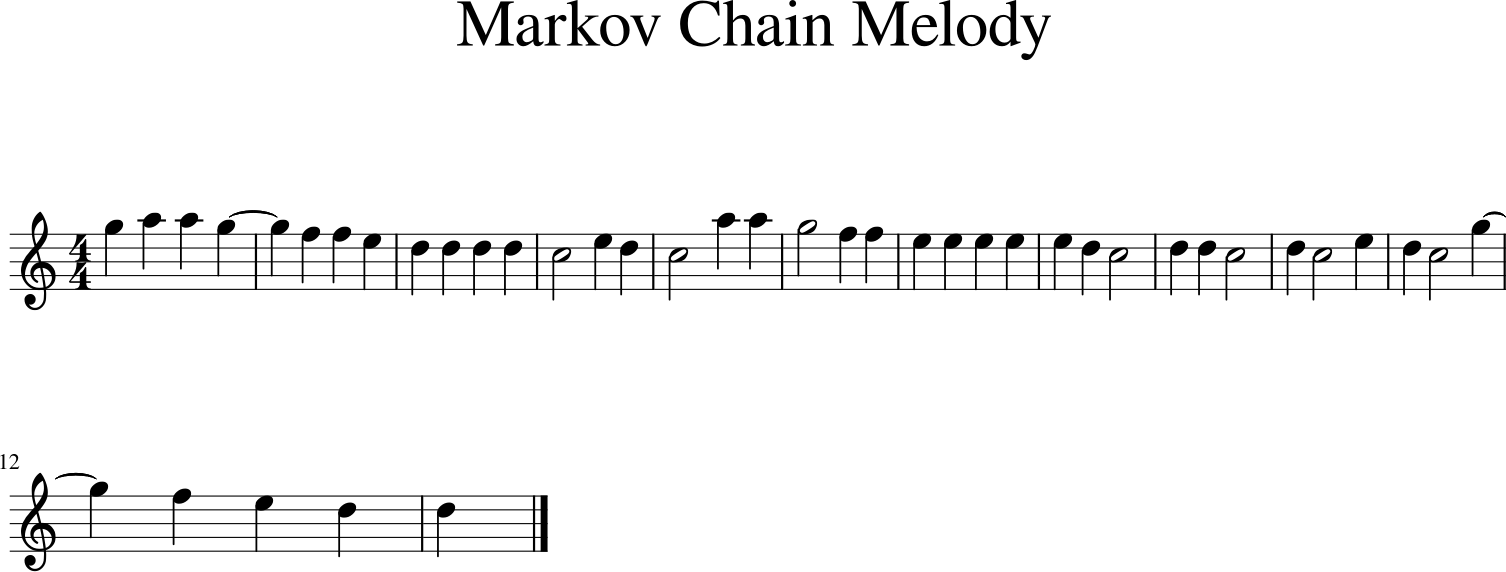

In [3]:
# Create the training melody.
training_data = create_training_data()

# Define the possible pitch-duration states.
# A quarter note and a half note of the same pitch are different states.
states = [
    ("C5", 1),
    ("D5", 1),
    ("E5", 1),
    ("F5", 1),
    ("G5", 1),
    ("A5", 1),
    ("C5", 2),
    ("D5", 2),
    ("E5", 2),
    ("F5", 2),
    ("G5", 2),
    ("A5", 2),
]

# Create a fresh model and train it once.
model = MarkovChainMelodyGenerator(states)
model.train(training_data)

# Try changing the number of generated notes.
NUMBER_OF_NOTES = 40

# Generate a melody and display its notation.
generated_melody = model.generate(NUMBER_OF_NOTES)
visualize_melody(generated_melody)